# Salmon

*Modeling and Simulation in Python*

Copyright 2021 Allen Downey

License: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)

In [1]:
# install Pint if necessary

try:
    import pint
except ImportError:
    !pip install pint

In [2]:
# download modsim.py if necessary

from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve
        local, _ = urlretrieve(url, filename)
        print('Downloaded ' + local)
    
download('https://github.com/AllenDowney/ModSimPy/raw/master/modsim.py')

In [3]:
# import functions from modsim

from modsim import *

## Can we predict salmon populations?

Each year the [U.S. Atlantic Salmon Assessment Committee](https://www.nefsc.noaa.gov/USASAC/Reports/USASAC2018-Report-30-2017-Activities.pdf) reports estimates of salmon populations in oceans and rivers in the northeastern United States.  The reports are useful for monitoring changes in these populations, but they generally do not include predictions.

The goal of this case study is to model year-to-year changes in population, evaluate how predictable these changes are, and estimate the probability that a particular population will increase or decrease in the next 10 years.

As an example, I'll use data from page 18 of the 2017 report, which provides population estimates for the Narraguagus and Sheepscot Rivers in Maine.

![USASAC_Report_2017_Page18](https://github.com/AllenDowney/ModSim/raw/main/data/USASAC_Report_2017_Page18.png)

There are tools for extracting data from a PDF document automatically, but for this example I will keep it simple and type it in.

Here are the population estimates for the Narraguagus River:

In [4]:
pops = [2749, 2845, 4247, 1843, 2562, 1774, 1201, 1284, 1287, 
        2339, 1177, 962, 1176, 2149, 1404, 969, 1237, 1615, 1201]

To get this data into a Pandas Series, I'll also make a range of years to use as an index.

In [5]:
years = linrange(1997, 2015)
years

array([1997., 1998., 1999., 2000., 2001., 2002., 2003., 2004., 2005.,
       2006., 2007., 2008., 2009., 2010., 2011., 2012., 2013., 2014.,
       2015.])

And here's the series.

In [6]:
pop_series = TimeSeries(pops, index=years)
pop_series

Time
1997.0    2749.0
1998.0    2845.0
1999.0    4247.0
2000.0    1843.0
2001.0    2562.0
2002.0    1774.0
2003.0    1201.0
2004.0    1284.0
2005.0    1287.0
2006.0    2339.0
2007.0    1177.0
2008.0     962.0
2009.0    1176.0
2010.0    2149.0
2011.0    1404.0
2012.0     969.0
2013.0    1237.0
2014.0    1615.0
2015.0    1201.0
Name: Quantity, dtype: float64

Here's what it looks like:

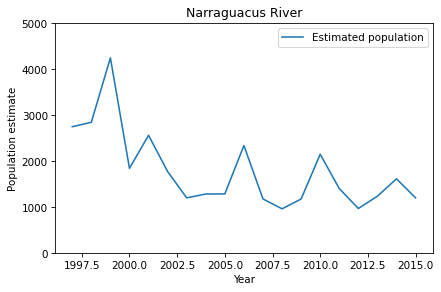

In [7]:
def plot_population(series):
    series.plot(label='Estimated population')
    decorate(xlabel='Year', 
             ylabel='Population estimate', 
             title='Narraguacus River',
             ylim=[0, 5000])
    
plot_population(pop_series)

## Modeling changes

To see how the population changes from year-to-year, I'll use `diff` to compute the absolute difference between each year and the next and `shift` to align the changes with the year they happened.

In [8]:
abs_diffs = pop_series.diff().shift(-1)
abs_diffs

Time
1997.0      96.0
1998.0    1402.0
1999.0   -2404.0
2000.0     719.0
2001.0    -788.0
2002.0    -573.0
2003.0      83.0
2004.0       3.0
2005.0    1052.0
2006.0   -1162.0
2007.0    -215.0
2008.0     214.0
2009.0     973.0
2010.0    -745.0
2011.0    -435.0
2012.0     268.0
2013.0     378.0
2014.0    -414.0
2015.0       NaN
Name: Quantity, dtype: float64

We can compute relative differences by dividing by the original series elementwise.

In [9]:
rel_diffs = abs_diffs / pop_series
rel_diffs

Time
1997.0    0.034922
1998.0    0.492794
1999.0   -0.566047
2000.0    0.390125
2001.0   -0.307572
2002.0   -0.322999
2003.0    0.069109
2004.0    0.002336
2005.0    0.817405
2006.0   -0.496794
2007.0   -0.182668
2008.0    0.222453
2009.0    0.827381
2010.0   -0.346673
2011.0   -0.309829
2012.0    0.276574
2013.0    0.305578
2014.0   -0.256347
2015.0         NaN
Name: Quantity, dtype: float64

These relative differences are observed annual net growth rates.
So let's drop the `NaN` and save them.

In [10]:
rates = rel_diffs.dropna()
rates

Time
1997.0    0.034922
1998.0    0.492794
1999.0   -0.566047
2000.0    0.390125
2001.0   -0.307572
2002.0   -0.322999
2003.0    0.069109
2004.0    0.002336
2005.0    0.817405
2006.0   -0.496794
2007.0   -0.182668
2008.0    0.222453
2009.0    0.827381
2010.0   -0.346673
2011.0   -0.309829
2012.0    0.276574
2013.0    0.305578
2014.0   -0.256347
Name: Quantity, dtype: float64

A simple way to model this system is to draw a random value from this series of observed rates each year.  We can use the NumPy function `choice` to make a random choice from a series.

In [11]:
np.random.choice(rates)

np.float64(-0.1826677994902294)

## Simulation

Now we can simulate the system by drawing random growth rates from the series of observed rates.

I'll start the simulation in 2015.

In [12]:
t_0 = 2015
p_0 = pop_series[t_0]

I'll create a `System` object with variables `t_0`, `p_0`, `rates`, and `duration=10` years. 

The series of observed rates is one big parameter of the model.

In [14]:
system = System(t_0=t_0,
                p_0=p_0,
                duration=10,
                rates=rates)

Write an update functon that takes as parameters `pop`, `t`, and `system`.
It should choose a random growth rate, compute the change in population, and return the new population.

In [15]:
def update_func1(pop, t, system):
    rate = np.random.choice(system.rates)
    
    return pop * (1 + rate)

Test your update function and run it a few times

In [16]:
update_func1(p_0, t_0, system)

np.float64(604.3510047028644)

Here's a version of `run_simulation` that stores the results in a `TimeSeries` and returns it.

In [17]:
def run_simulation(system, update_func):
    """Simulate a queueing system.
    
    system: System object
    update_func: function object
    """
    t_0 = system.t_0
    t_end = t_0 + system.duration
    
    results = TimeSeries()
    results[t_0] = system.p_0
    
    for t in linrange(t_0, t_end):
        results[t+1] = update_func(results[t], t, system)

    return results

Use `run_simulation` to run generate a prediction for the next 10 years.

Then plot your prediction along with the original data.  Your prediction should pick up where the data left off.

<Axes: title={'center': 'Narraguacus River'}, xlabel='Time', ylabel='Population estimate'>

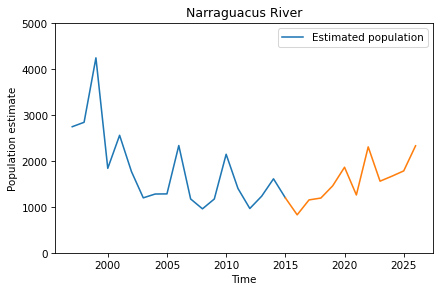

In [18]:
results = run_simulation(system, update_func1)

# Plot original data
plot_population(pop_series)

# Plot prediction on top
results.plot(label='Prediction', color='C1')

To get a sense of how much the results vary, we can run the model several times and plot all of the results.

In [19]:
def plot_many_simulations(system, update_func, iters):
    """Runs simulations and plots the results.
    
    system: System object
    update_func: function object
    iters: number of simulations to run
    """
    for i in range(iters):
        results = run_simulation(system, update_func)
        results.plot(color='gray', label='', linewidth=1, alpha=0.3)

The plot option `alpha=0.1` makes the lines semi-transparent, so they are darker where they overlap.

Run `plot_many_simulations` with your update function and `iters=30`.  Also plot the original data.

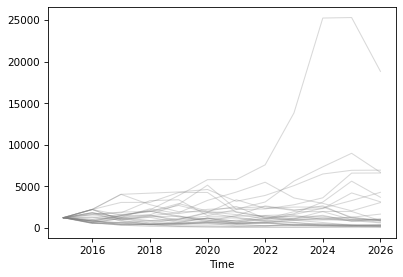

In [20]:
plot_many_simulations(system=system, update_func=update_func1, iters=30) 

The results are highly variable: according to this model, the population might continue to decline over the next 10 years, or it might recover and grow rapidly!

It's hard to say how seriously we should take this model.  There are many factors that influence salmon populations that are not included in the model.  For example, if the population starts to grow quickly, it might be limited by resource limits, predators, or fishing.  If the population starts to fall, humans might restrict fishing and stock the river with farmed fish.

So these results should probably not be considered useful predictions.  However, there might be something useful we can do, which is to estimate the probability that the population will increase or decrease in the next 10 years.  

## Distribution of net changes

To describe the distribution of net changes, write a function called `run_many_simulations` that runs many simulations, saves the final populations in a `SweepSeries`, and returns the `SweepSeries`.

In [21]:
def run_many_simulations(system, update_func, iters):
    """Runs simulations and report final populations.
    
    system: System object
    update_func: function object
    iters: number of simulations to run
    
    returns: series of final populations
    """

    results = SweepSeries()

    for i in range(iters):
        sim_results = run_simulation(system, update_func)
        results[i] = sim_results.iloc[-1]

    return results

Test your function by running it with `iters=5`.

In [22]:
result = run_many_simulations(system, update_func1, 5)
result

Parameter
0     165.460826
1     285.238471
2       7.473680
3    1915.316453
4     623.593246
Name: Metric, dtype: float64

Now we can run 1000 simulations and describe the distribution of the results.

In [23]:
last_pops = run_many_simulations(system, update_func1, 1000)
last_pops.describe()

count      1000.000000
mean       2006.415676
std        5389.541635
min           6.837029
25%         327.190621
50%         755.711167
75%        1953.665447
max      123888.873112
Name: Metric, dtype: float64

If we substract off the initial population, we get the distribution of changes.

In [24]:
net_changes = last_pops - p_0
net_changes.describe()

count      1000.000000
mean        805.415676
std        5389.541635
min       -1194.162971
25%        -873.809379
50%        -445.288833
75%         752.665447
max      122687.873112
Name: Metric, dtype: float64

The median is negative, which indicates that the population decreases more often than it increases.

We can be more specific by counting the number of runs where `net_changes` is positive.

In [25]:
np.sum(net_changes > 0)

np.int64(368)

Or we can use `mean` to compute the fraction of runs where `net_changes` is positive.

In [26]:
np.mean(net_changes > 0)

np.float64(0.368)

And here's the fraction where it's negative.

In [27]:
np.mean(net_changes < 0)

np.float64(0.632)

So, based on observed past changes, this model predicts that the population is more likely to decrease than increase over the next 10 years, by about 2:1.

## A refined model

There are a few ways we could improve the model.

1.  It looks like there might be cyclic behavior in the past data, with a period of 4-5 years.  We could extend the model to include this effect.

2.  Older data might not be as relevant for prediction as newer data, so we could give more weight to newer data.

The second option is easier to implement, so let's try it.

I'll use `linspace` to create an array of "weights" for the observed rates.  The probability that I choose each rate will be proportional to these weights.

The weights have to add up to 1, so I divide through by the total.

In [31]:
weights = linspace(0, 1, len(rates))
weights /= sum(weights)
weights

array([0.        , 0.00653595, 0.0130719 , 0.01960784, 0.02614379,
       0.03267974, 0.03921569, 0.04575163, 0.05228758, 0.05882353,
       0.06535948, 0.07189542, 0.07843137, 0.08496732, 0.09150327,
       0.09803922, 0.10457516, 0.11111111])

I'll add the weights to the `System` object, since they are parameters of the model.

In [32]:
system.weights = weights

We can pass these weights as a parameter to `np.random.choice` (see the [documentation](https://docs.scipy.org/doc/numpy/reference/generated/numpy.random.choice.html))

In [33]:
np.random.choice(system.rates, p=system.weights)

np.float64(0.8273809523809523)

Write an update function that takes the weights into account.

In [38]:
def update_func_weighted(pop, t, system):
    rate = np.random.choice(system.rates, p=system.weights)
    
    return pop * (1 + rate)

Use `plot_many_simulations` to plot the results.

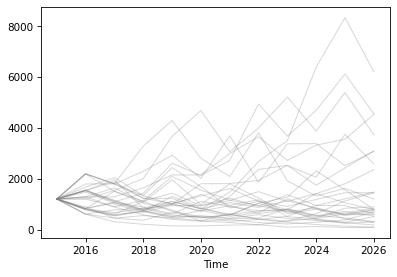

In [39]:
plot_many_simulations(system=system, update_func=update_func_weighted, iters=30) 

Use `run_many_simulations` to collect the results and `describe` to summarize the distribution of net changes.

In [40]:
last_pops = run_many_simulations(system, update_func1, 1000)
net_changes = last_pops - p_0
net_changes.describe()

count     1000.000000
mean       545.734892
std       2864.294349
min      -1193.920425
25%       -925.055524
50%       -458.545490
75%        603.871695
max      21881.468588
Name: Metric, dtype: float64

In [41]:
np.mean(net_changes < 0)

np.float64(0.648)

Does the refined model have much effect on the probability of population decline?

The refined model does NOT meaningfully change the probability of population decline.

- Unweighted model: ~63% probability of decline
- Weighted model: 64.8% probability of decline

Both models point to the same headline conclusion: the salmon population is more likely to decline than grow over the next 10 years.

The refinement does, however, narrow the range of possible outcomes 
(standard deviation dropped from 5389 to 2864) by emphasizing recent rates and 
de-emphasizing extreme historical growth years. So while the central probability 
is unchanged, we have a more confident estimate with less extreme tail outcomes.